# Comparing training supports in the five-slot identity format (no training)

Transformer AR and Looped AR trained on k ∈ {0,2} (nb 12), {0,2,3} (nb 13), {0,2,3,4} (nb 14) and {0,2,3,4,5} (nb 10).
This notebook only READS saved predictions.

**Checked before comparing:**
* the same test manifest;
* identical test records and targets;
* the same model configuration.

**Notebook 10 caveat:** it used a different training stream (20% per k, not the per-k indexed stream), so its run is
not stream-matched to 12–14.

**Reported:**
* exact accuracy by k, with trained vs held-out marked;
* singletons by operation × placement;
* k=5 split by whether the word's transformation appears in training;
* correctness transitions between consecutive supports on identical test records.

One seed: descriptive only.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: c2b26dcd9ffd54505f439c6820dfc903d0e2b323


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
SEED = 42
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")


Mounted at /content/drive


not yet available: train02/transformer_ar, train02/looped_transformer_ar
compatibility: OK (same manifest, identical test records and targets, same model config per model)
written to /content/drive/MyDrive/decompositionality_results/support_comparison/seed_42


,support,model,n_records,manifest_hash,model_hash,selected_step,test_records_identical_to_reference,training_stream
0,train023,transformer_ar,376000,bdf24c327a65,b8c7a0906c8420d2,5000,True,per-k indexed (idext)
1,train023,looped_transformer_ar,376000,bdf24c327a65,76a3940b2ffbff78,5000,True,per-k indexed (idext)
2,train0234,transformer_ar,376000,bdf24c327a65,b8c7a0906c8420d2,5000,True,per-k indexed (idext)
3,train0234,looped_transformer_ar,376000,bdf24c327a65,76a3940b2ffbff78,4750,True,per-k indexed (idext)
4,train02345,transformer_ar,376000,bdf24c327a65,b8c7a0906c8420d2,5000,True,notebook-10 stream (20% per k; NOT the per-k i...
5,train02345,looped_transformer_ar,376000,bdf24c327a65,76a3940b2ffbff78,5000,True,notebook-10 stream (20% per k; NOT the per-k i...


k                                    0      1     2      3      4       5
model                 support                                            
looped_transformer_ar train023    1000      0  9000  27000      0     672
                      train0234   1000      0  9000  27000  80999       0
                      train02345  1000  14858  9000  26996  80939  242576
transformer_ar        train023    1000      0  9000  27000      0    3029
                      train0234   1000   3796  9000  27000  81000    6363
                      train02345  1000  15000  9000  27000  81000  243000

,support,model,k,status,transform_in_training,exact_correct,n,exact_acc
2,train023,transformer_ar,1,HELD OUT,True,0,15000,0.000000
3,train023,transformer_ar,1,HELD OUT,False,0,0,NaN
6,train023,transformer_ar,3,seen,True,27000,27000,1.000000
7,train023,transformer_ar,3,seen,False,0,0,NaN
8,train023,transformer_ar,4,HELD OUT,True,0,38000,0.000000
9,train023,transformer_ar,4,HELD OUT,False,0,43000,0.000000
10,train023,transformer_ar,5,HELD OUT,True,3029,162000,0.018698
11,train023,transformer_ar,5,HELD OUT,False,0,81000,0.000000
14,train023,looped_transformer_ar,1,HELD OUT,True,0,15000,0.000000
15,train023,looped_transformer_ar,1,HELD OUT,False,0,0,NaN


,pair,model,k,status,n,before_exact,after_exact,both_correct,gained,lost,both_wrong
0,train02 -> train023,transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,train02 -> train023,looped_transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,train023 -> train0234,transformer_ar,0,NaN,1000.0,1000.0,1000.0,1000.0,0.0,0.0,0.0
3,train023 -> train0234,transformer_ar,1,NaN,15000.0,0.0,3796.0,0.0,3796.0,0.0,11204.0
4,train023 -> train0234,transformer_ar,2,NaN,9000.0,9000.0,9000.0,9000.0,0.0,0.0,0.0
5,train023 -> train0234,transformer_ar,3,NaN,27000.0,27000.0,27000.0,27000.0,0.0,0.0,0.0
6,train023 -> train0234,transformer_ar,4,NaN,81000.0,0.0,81000.0,0.0,81000.0,0.0,0.0
7,train023 -> train0234,transformer_ar,5,NaN,243000.0,3029.0,6363.0,0.0,6363.0,3029.0,233608.0
8,train023 -> train0234,looped_transformer_ar,0,NaN,1000.0,1000.0,1000.0,1000.0,0.0,0.0,0.0
9,train023 -> train0234,looped_transformer_ar,1,NaN,15000.0,0.0,0.0,0.0,0.0,0.0,15000.0


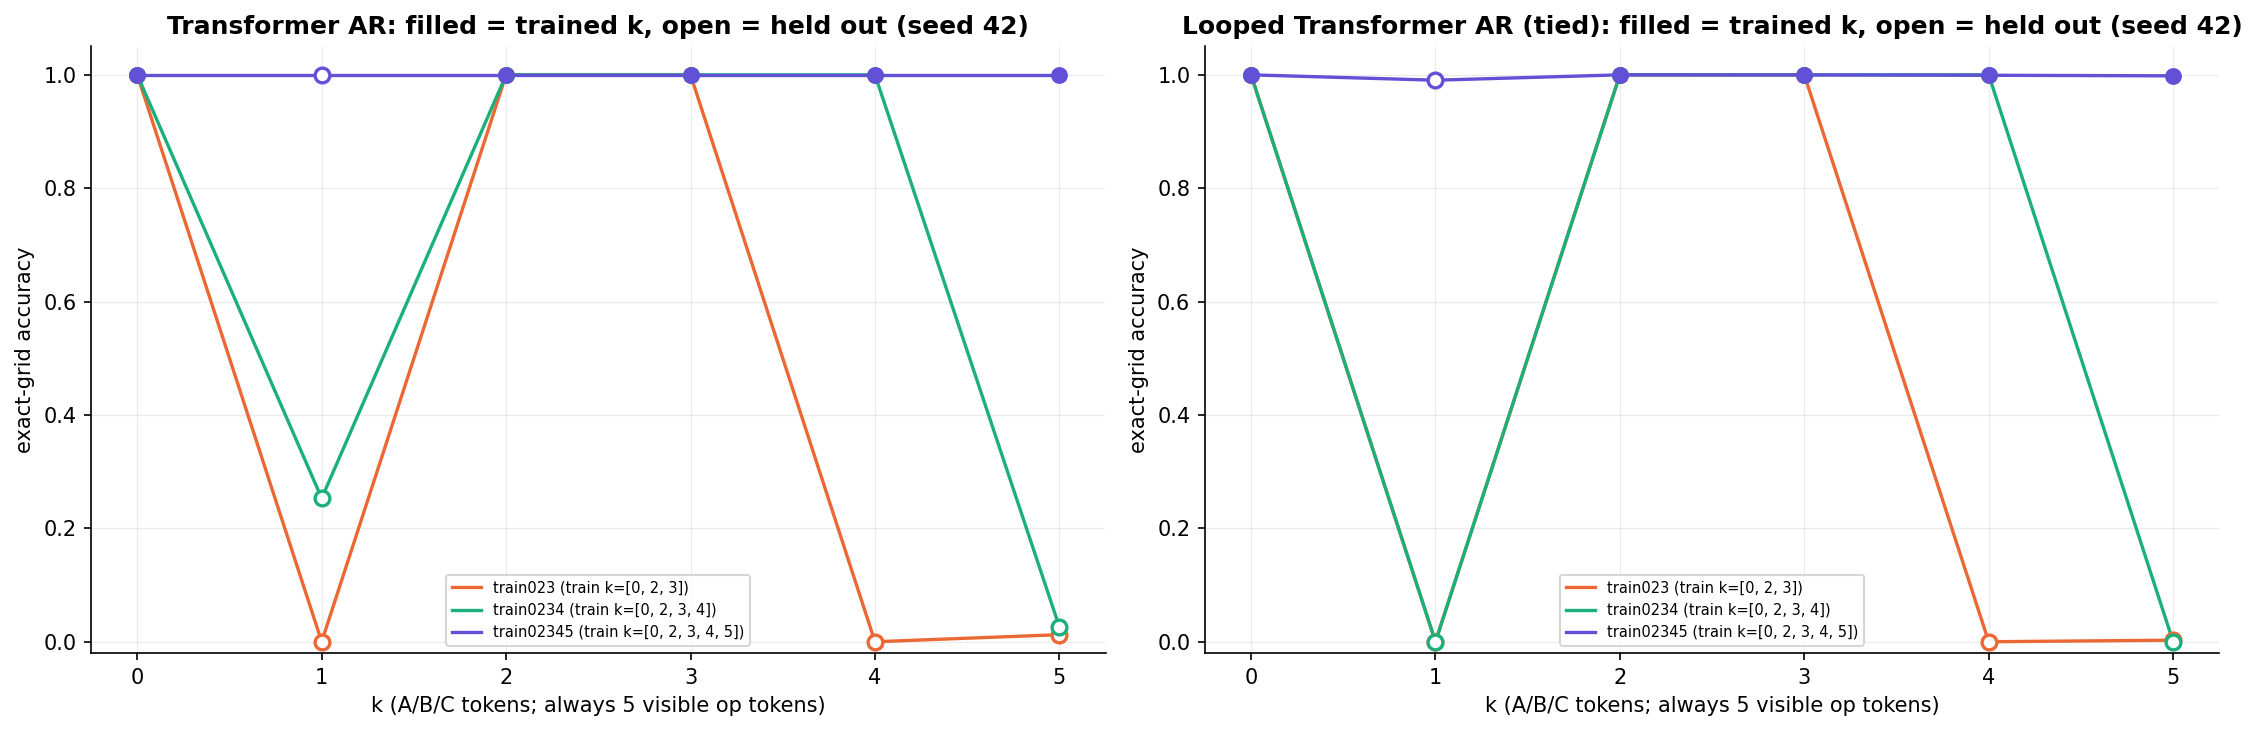

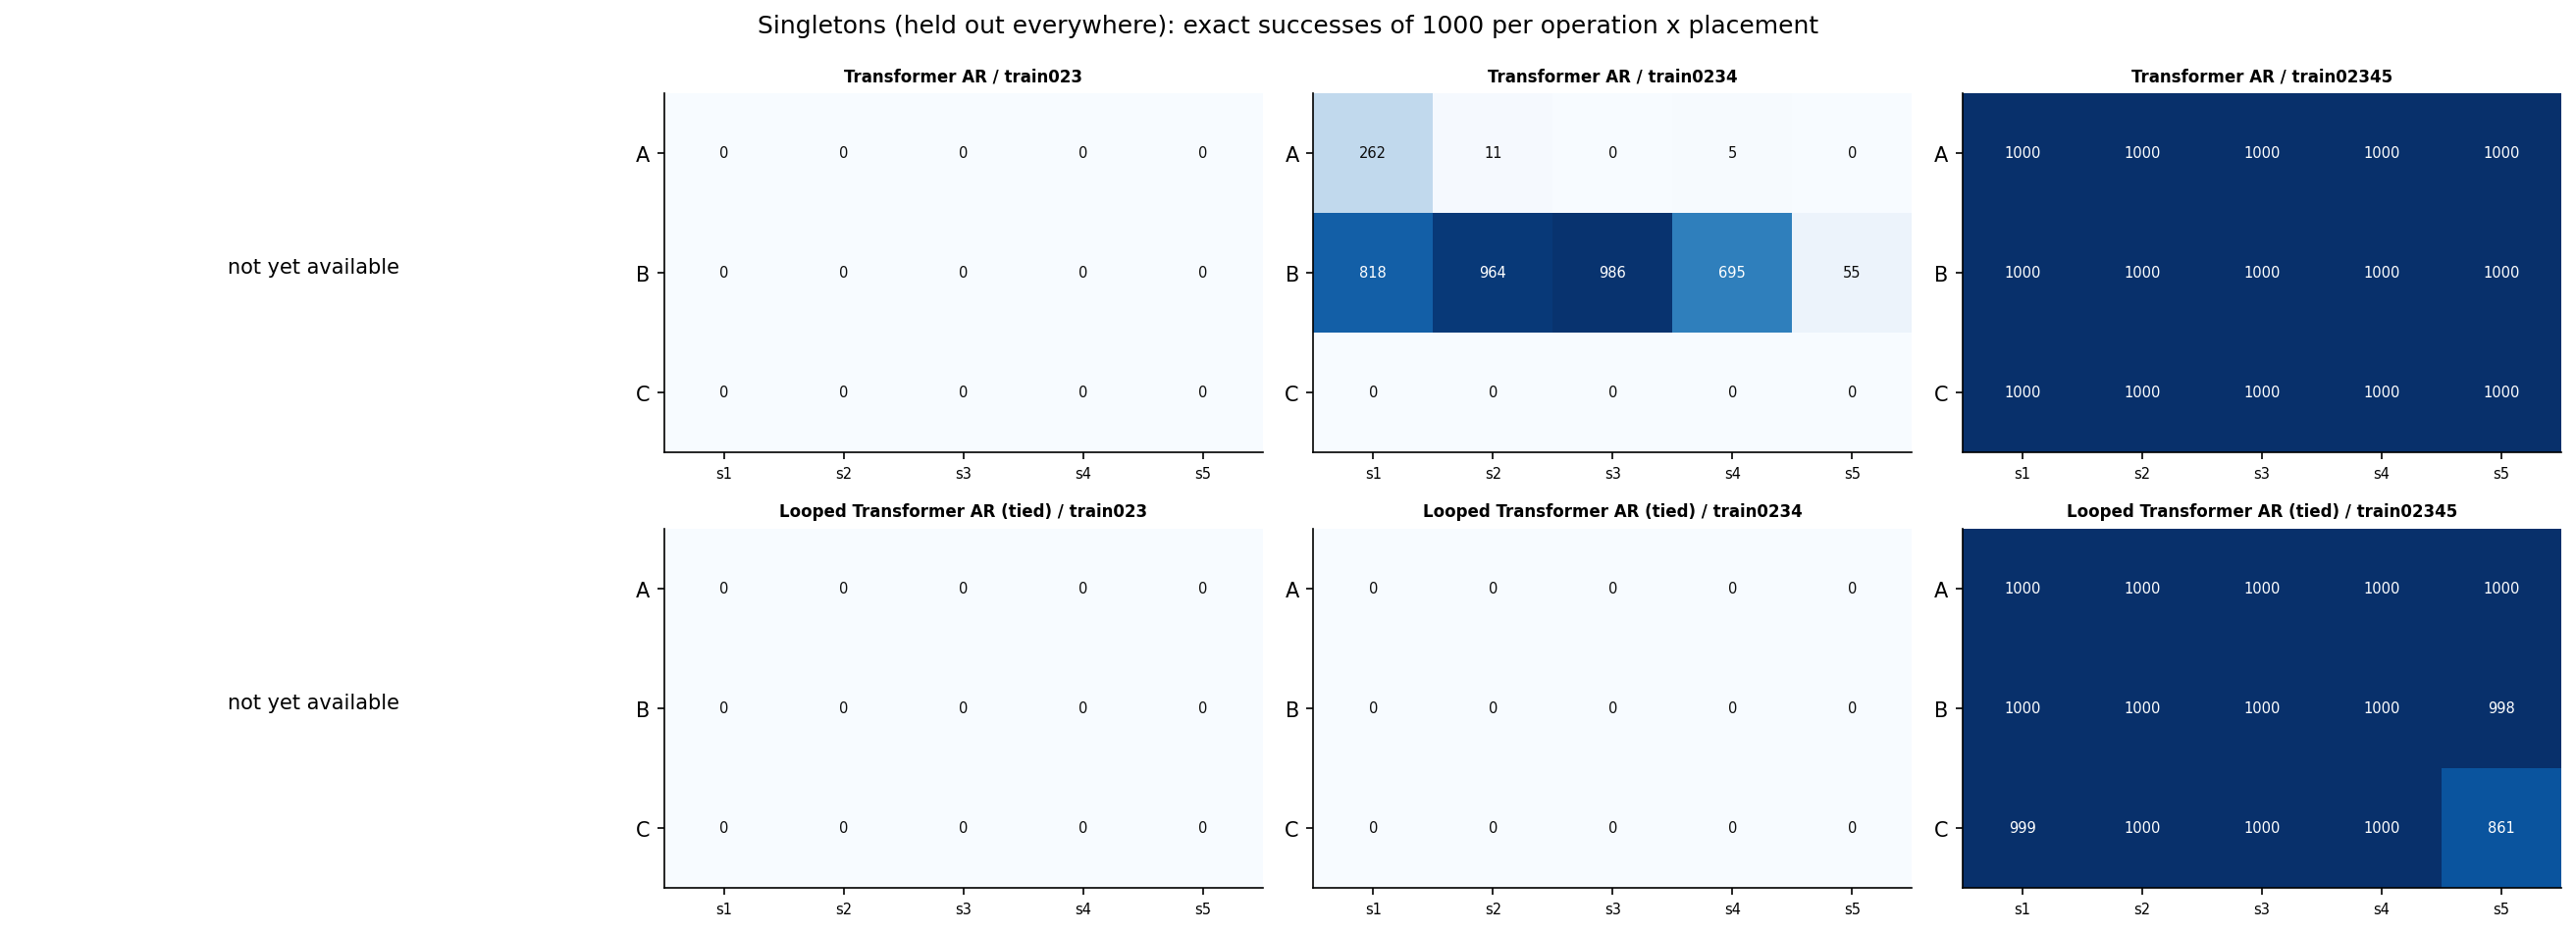

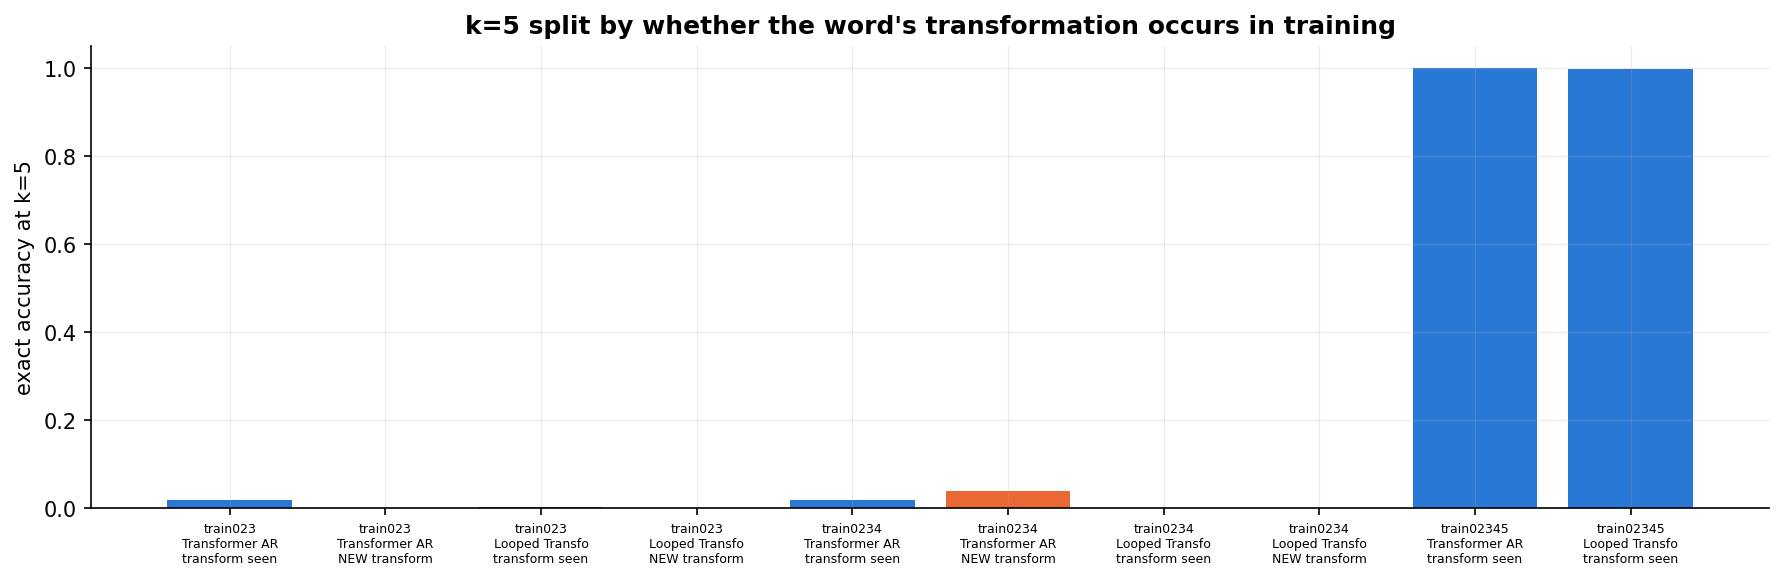

In [3]:
# --- Compare (read-only) ----------------------------------------------------------------------------------------
import pandas as pd
from IPython.display import Image, display
from decompositionality.support_comparison import run
pd.set_option("display.max_rows", 200); pd.set_option("display.width", 250)
R = run(RESULTS_ROOT, SEED)
if "compatibility" in R:
    display(R["compatibility"])
    display(R["by_k"].pivot_table(index=["model", "support"], columns="k", values="exact_correct", aggfunc="first"))
    display(R["transform_split"][R["transform_split"].k.isin([1, 3, 4, 5])])
    display(R["transitions"])
    for p in R["figures"]:
        if str(p).endswith(".png"):
            display(Image(filename=str(p)))


Outputs: `<RESULTS_ROOT>/support_comparison/seed_42/` (CSV tables + figures).